# Exercise 1: From municipalities to counties

Each Norwegian municipality (*kommune*) belongs to a county (*fylke*). In this
exercise, you will use municipality-level data from Statistics Norway (SSB) to
compare counties by their number of municipalities, population, and population
density.

1.  Load `municipalities.csv` from the `data/ssb/` folder. Keep only the columns
    `municipality`, `county`, `population`, and `land_area`, and display the first
    five rows.

    Each row represents one municipality. The column `population` records its
    number of residents, and `land_area` records its land area in km².

2.  Group the data by `county` and count the municipalities in each county.
    Display the counts in descending order. Which county contains the most
    municipalities?

    *Hint:* Applying `size()` to a grouped DataFrame counts the rows in each group.
    Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the counts.

3.  Create a DataFrame named `df_counties` containing the total population and
    total land area of each county. Report the three counties with the largest
    populations.

    Check that summing the county populations gives the same national total as
    summing the municipality populations.

4.  Add a column named `density` to `df_counties`, containing each county's
    population density in residents per km² of land:

    $$
    \text{Population density} =
    \frac{\text{Total population}}{\text{Total land area}}
    $$

    Report the three counties with the highest population densities. Does the
    county with the largest population also have the highest population density?

### 1. 

In [1]:
import pandas as pd

In [ ]:
DATA_PATH = '../../data'

file = f'{DATA_PATH}/ssb/municipalities.csv'

#TODO: read in the data and inspect it

In [ ]:
#df1 = pd.read_csv(file)

In [ ]:
columns = ['municipality','county','population','land_area']
df = pd.read_csv(file, usecols=columns)

df.head()

,municipality,county,population,land_area
0,Oslo,Oslo,724290,426
1,Bergen,Vestland,293709,445
2,Trondheim - Tråante,Trøndelag - Trööndelage,216518,496
3,Stavanger,Rogaland,150123,256
4,Bærum,Akershus,132358,189


### 2. 

In [25]:
#group by county

groups = df.groupby('county')
counts = groups.size().sort_values(ascending=False)
counts


county
Innlandet                           46
Vestland                            43
Nordland - Nordlánnda               41
Trøndelag - Trööndelage             38
Møre og Romsdal                     27
Agder                               25
Rogaland                            23
Akershus                            21
Troms - Romsa - Tromssa             21
Finnmark - Finnmárku - Finmarkku    18
Buskerud                            18
Telemark                            17
Østfold                             12
Vestfold                             6
Oslo                                 1
dtype: int64

### 3.

In [37]:
#compute total poulation and land area

df_counties = groups[['population', 'land_area']].sum()

df_counties.sort_values('population', ascending=False).head(3)

,population,land_area
county,,
Akershus,740680,5471
Oslo,724290,426
Vestland,655210,31964


In [38]:
sum1 = df['population'].sum()
sum2 = df_counties['population'].sum()

sum1==sum2

np.True_

### 4.

In [48]:
# Compute population. density

df_counties['density'] = df_counties['population'] / df_counties['land_area']

df_counties['density'].sort_values(ascending=False).head(3)

county
Oslo        1700.211268
Akershus     135.382928
Vestfold     123.360899
Name: density, dtype: float64

***
# Exercise 2: House price levels and dispersion

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    To familiarize yourself with the data, report the columns present in the DataFrame and 
    then restrict the data to the columns `SalePrice` (price in thousands of US dollars) 
    and `Neighborhood` (abbreviated name of the neighborhood).
    
    Count the number of observations in each neighborhood. Drop all observations
    belonging to neighborhoods with fewer than 20 observations. Use this
    restricted data set for the remainder of the exercise.

    Check that there are no observations with missing values in the final data set.

2.  Compute the average house price (column `SalePrice`) by neighborhood (column
    `Neighborhood`). List the three neighborhoods with the highest average prices,
    for example by using
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

    Create a bar chart showing the average sale price for all remaining
    neighborhoods in descending order.

    *Hint:* You can create the bar chart by either using pandas's 
    [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html)
    or Matplotlib's
    [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).

3.  You want to quantify the price dispersion in each neighborhood. To this end, compute the standard deviation of the sale price by neighborhood using 
    [`std()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html).
    Which are the three neighborhoods with the most dispersed prices?

4.  Create a scatter plot with the average house price on the $x$-axis and the standard deviation on the $y$-axis.
    Is there a relationship between the average house prices and their dispersion within a neighborhood?

    *Hint:* You can create the scatter plot by either using pandas's 
    [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
    or Matplotlib's 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  **[Advanced]** To compare neighborhoods with different average prices,
    express the standard deviation as a percentage of the average price:

    $$
    \text{Relative price spread (\%)} =
    100 \times \frac{\text{standard deviation}}{\text{average price}}
    $$

    This is the
    [coefficient of variation](
    https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/coefvari.htm
    )
    expressed as a percentage. For example, a standard deviation of 20 thousand
    USD and an average price of 100 thousand USD give a relative spread of 20%.

    Calculate the relative price spread for each neighborhood. Create a scatter
    plot with the average house price on the $x$-axis and the relative price spread
    on the $y$-axis. Do neighborhoods with higher average prices also have more
    dispersed prices relative to their average? Compare the pattern with Part 4.

***
# Exercise 3: Determinants of house prices

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa, to understand how house prices vary
with selected house characteristics.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    Keep only the columns `SalePrice` (price in thousands of US dollars), `LotArea` (lot area in m²), `YearBuilt`, and `Bedrooms` (number of bedrooms).

    Restrict your data set to houses with one or more bedrooms and a lot area of at least 100 m².
    Report the sample size after applying these restrictions.

2.  Compute the average year in which a house was built (using the column `YearBuilt`). 

    Classify houses as _"newer"_ if they were built after the sample's average
    construction year, and _"older"_ otherwise. Store this classification in a new
    column `Newer`, with 1 for newer houses and 0 for older houses.

    What is the average year of construction within these two categories?

3.  Create a new column `Rooms` which categorizes the number of `Bedrooms` into
    three groups: 1–2, 3, and 4 or more. Use the values 2, 3, and 4 to represent
    these groups. You can create these categories using boolean indexing,
    [`np.where()`](https://numpy.org/doc/2.0/reference/generated/numpy.where.html),
    pandas's
    [`where()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.where.html),
    [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
    [`clip()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html),
    or some other way.

4.  Compute the mean sale price and number of observations within each group
    formed by `Newer` and `Rooms` (for a total of 6 different categories).

    By how much does the average price of newer houses with 4+ bedrooms exceed that
    of older houses with 1–2 bedrooms?

5.  Create a figure with two subplots arranged in two columns. The left column
    should contain a bar chart showing the average house price by the number of
    bedrooms (1–2, 3, 4+) for _older_ houses, whereas the right column should show the
    corresponding bars for _newer_ houses. Use a shared vertical scale so that prices
    can be compared across the two panels.

***
# Exercise 4: Inflation and unemployment in the US

In this exercise, you'll be working with monthly observations of selected
macroeconomic variables for the United States obtained from
[FRED](https://fred.stlouisfed.org/).
The data set starts in 1948 and contains observations for a total of 936 months.

1.  Load the data from the file `FRED_monthly.csv` located in the `data/FRED`
    folder. Parse `DATE` as dates and use it as the DataFrame index. Sort the
    observations in chronological order, then print the first 10 observations to
    get an idea of what the data looks like.

    Keep only the columns `Year`, `Month`, `CPI`, and `UNRATE`, retaining the date
    index. Perform this analysis only on observations prior to 1970 and drop the
    rest, leaving the sample period 1948–1969.

2.  The column `CPI` stores the consumer price index (CPI) for the US.
    Create a new column `Inflation` which contains _year-over-year inflation in
    percent_: the percent change in the CPI relative to the same month in the
    previous year. Apply
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    to the column `CPI`.

    *Hints:*

    -   Since this is monthly data, pass `periods=12` to `pct_change()` to get
        year-over-year changes.
    -   Multiply the values returned by `pct_change()` by 100 to get percent
        values.

3.  Compute the average unemployment rate (column `UNRATE`) over the restricted
    1948–1969 sample. Create a new column `UNRATE_HIGH` that contains an indicator
    whenever the unemployment rate is above its average value
    (_"high unemployment period"_).

    -   How many observations fall into the high- and low-unemployment periods?
    -   What is the average unemployment rate in the high- and low-unemployment periods?

4.  Compute the average year-over-year inflation rate for high- and
    low-unemployment periods using the available observations. Is there any
    difference?

    Visualize this relationship by creating a scatter plot with the unemployment rate on the $x$-axis and inflation on the $y$-axis, and assign different colors 
    to observations from the low- and high-unemployment periods.

5.  Use 
    [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
    to compute the calendar-year average of the monthly year-over-year inflation
    rates.

    -   Report the three years with the highest averages.
    -   Create a plot that shows these calendar-year averages over the sample period.

    *Hint:* Use the resampling rule `'YE'` when calling `resample()`.

***
# Exercise 5: From ship arrivals to seasonal traffic

In this exercise, you're asked to aggregate individual ship arrivals to compare
vessel categories and seasonal traffic patterns. For this, we're using data from
Kystverket on reported arrivals at Bergen harbor for the complete calendar years
2013–2025. Each row represents one arrival, including repeat visits by the same
ship.

The file `kystverket/bergen_arrivals.csv.gz` contains four columns:

- `arrival`: Reported arrival time in Bergen local time.
- `vessel_type`: Detailed vessel type.
- `vessel_category`: Broad vessel category, such as passenger ships or
  cargo ships.
- `gross_tonnage`: Gross tonnage (GT), a measure of vessel size based on
  enclosed volume.

See the [data description](../../data/kystverket/README.md) for details.
Note that the extension `.csv.gz` indicates that the file is compressed in order to reduce the file size.

Run the supplied loading cell, then complete these tasks:

1.  Display the first five rows and report the total number of arrivals.

2.  Count arrivals by `vessel_category` and calculate each category's percentage
    of all arrivals. Display the results in descending order of arrival counts
    and create a horizontal bar chart of the counts.

    *Hint:* Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the arrival counts.

    *Hint:* You can use either `plt.barh()` or `DataFrame.plot.barh()` to create the bar chart.

3.  Compute the mean `gross_tonnage` for each `vessel_category`. Display all
    categories in descending order of mean gross tonnage and create a horizontal
    bar chart of these means.

4.  Count arrivals in each month separately for `Passenger ships` and
    `Cargo ships`. Store the results in a DataFrame named `df_monthly`, with one
    column per category, and plot both monthly series in one line chart.

    *Hint:* There are several ways to implement this. One way is to compute the monthly counts for each category separately and then combine the results into a single DataFrame.

5.  Use `groupby()` to calculate average monthly arrivals for each calendar
    month, from January through December. Create two seasonal bar charts, one
    per category, with a shared vertical scale. Describe the contrast in one
    sentence.

    *Hint:* Group `df_monthly` by `df_monthly.index.month`. Replace the resulting index with the supplied `month_names`. 
    
    *Hint:* Use
    `plot.bar(subplots=True, layout=(1, 2), sharey=True)` for the two panels when plotting with the pandas plotting API.

In [ ]:
import pandas as pd

# Relative path to the data directory
DATA_PATH = '../../data'
# Path to the compressed Bergen arrivals CSV file
file = f'{DATA_PATH}/kystverket/bergen_arrivals.csv.gz'

# Parse arrival times and prepare a chronological date index
df_arrivals = pd.read_csv(file, parse_dates=['arrival'], index_col='arrival')

# Sort arrivals in chronological order
df_arrivals = df_arrivals.sort_index()

# Labels for the seasonal bar charts
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
]

### 1.

In [51]:
df_arrivals.head()

,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0


In [61]:
counts = df_arrivals.groupby('vessel_category').size()
counts

vessel_category
Cargo ships                             17799
Fishing vessels                           995
Offshore and special-purpose vessels    12953
Passenger ships                         10141
Recreational vessels                       50
Tankers                                  3488
Unknown                                   194
dtype: int64

In [ ]:
#df_arrivals.value_counts('vessel_category')

np.int64(45620)

In [65]:
total = len(df_arrivals)
shares = counts/total * 100

In [66]:
shares

vessel_category
Cargo ships                             39.015783
Fishing vessels                          2.181061
Offshore and special-purpose vessels    28.393249
Passenger ships                         22.229285
Recreational vessels                     0.109601
Tankers                                  7.645769
Unknown                                  0.425252
dtype: float64

In [80]:
#Put totsal arrivals and shares into a DF

df_categories = pd.DataFrame({'arrivals':counts, 'share_percent':shares})
df_categories = df_categories.sort_values('arrivals',ascending=False)
df_categories


,arrivals,share_percent
vessel_category,,
Cargo ships,17799,39.015783
Offshore and special-purpose vessels,12953,28.393249
Passenger ships,10141,22.229285
Tankers,3488,7.645769
Fishing vessels,995,2.181061
Unknown,194,0.425252
Recreational vessels,50,0.109601


In [71]:
import matplotlib.pyplot as plt

<Axes: ylabel='vessel_category'>

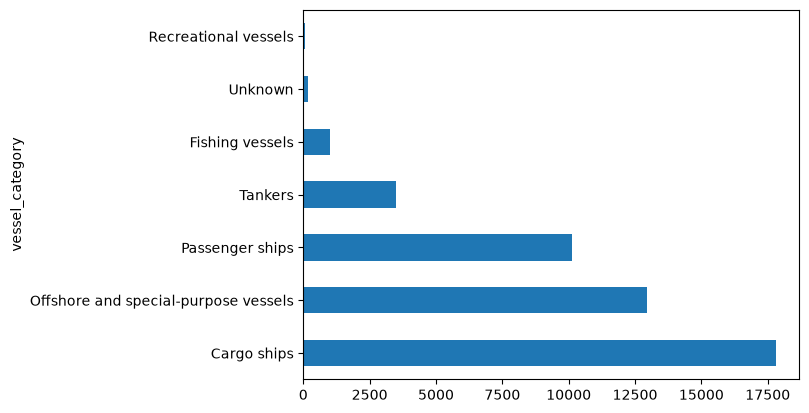

In [81]:
#arrivals = (df_categories['arrivals']).array

df_categories['arrivals'].plot.barh()

### 3. 


In [84]:
df_arrivals

,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0
...,...,...,...
2025-12-31 15:45:00,Passenger/Ro-Ro Ship (Vehicles),Passenger ships,15519.0
2025-12-31 16:00:00,Offshore Tug/Supply Ship,Offshore and special-purpose vessels,4183.0
2025-12-31 18:00:00,Tug,Offshore and special-purpose vessels,302.0


In [91]:
avg_tonnage = df_arrivals.groupby('vessel_category')['gross_tonnage'].mean()

avg_tonnage = avg_tonnage.sort_values(ascending=False)

In [92]:
avg_tonnage 

vessel_category
Passenger ships                         36060.081294
Cargo ships                              5156.656160
Offshore and special-purpose vessels     4862.774166
Tankers                                  2171.372133
Fishing vessels                          1636.176884
Unknown                                  1120.031088
Recreational vessels                       95.306122
Name: gross_tonnage, dtype: float64

<Axes: ylabel='vessel_category'>

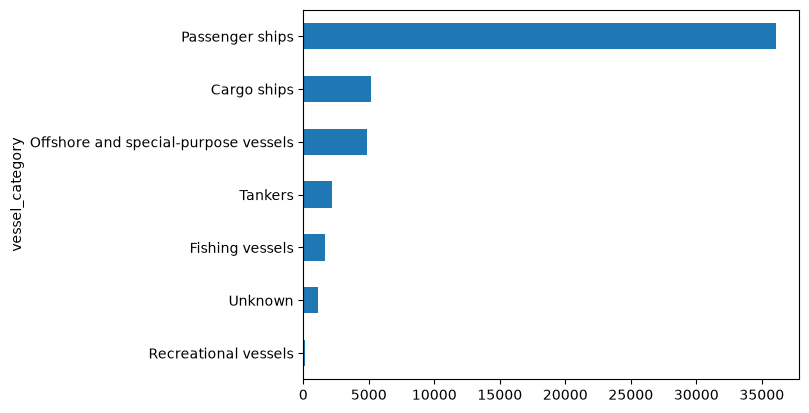

In [95]:
#Create bar chart

avg_tonnage.sort_values().plot.barh()

### Part 4

In [110]:
df_p = df_arrivals.groupby('vessel_type')

#df_arrivals.resample('ME').size()

In [112]:
categories = ['Passanger ships', 'Cargo ships']

arrivals_dict = {}

for category in categories:

    keep = df_arrivals['vessel_category'] == category
    df_ = df_arrivals[keep]
    arrivals = df_arrivals.resample('ME').size()
    #save current monthly arrivals in dictionary 
    arrivals_dict[category] = arrivals


<Axes: xlabel='arrival'>

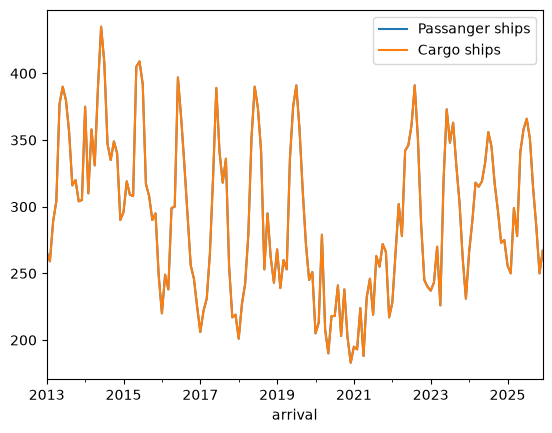

In [116]:
#arrivals_dict
#convert to dataframe

df = pd.DataFrame(arrivals_dict)

df.plot.line()